In [1]:
# --- VaccineScout configuration -------------------------------------------
# Makes scripts/ importable regardless of where the kernel was started, then
# loads every path and parameter from config.yaml at the repository root.
import sys
from pathlib import Path

_SCRIPTS_DIR = Path.cwd() if (Path.cwd() / "config_loader.py").is_file() else Path.cwd() / "scripts"
_SCRIPTS_DIR = _SCRIPTS_DIR.resolve()
if str(_SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(_SCRIPTS_DIR))

from config_loader import load_config

cfg = load_config()
print(f"Loaded config from {cfg.config_path}")

FITNESS_COLUMN = cfg.fitness_column

import pandas as pd
import matplotlib.pyplot as plt
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import subprocess
import sys
from pathlib import Path

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")


Loaded config from /home/pgangwar@AD.UCSD.EDU/FutureCoV/config.yaml


In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = cfg.data_root_str
DATA_PATH = cfg.file("final_df")

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(cfg.file("sequence_dict"))

refSeq = getReference(cfg.file("ref_spike_genome"))

fda_df = pd.read_pickle(cfg.file("fda_recommendations"))

ver = cfg.pyro_version

pyro_df = pd.read_pickle(cfg.pyro_spike_pickle(ver))

In [4]:
# --- Define cutoff date ---
cutoff_date = cfg.cutoff_date
cohort_dir = cfg.cutoff_dir(cutoff_date)
current_dict = cfg.cohort_file(cutoff_date, "current_id_to_seq")
dist_parquet = cfg.cohort_file(cutoff_date, "pairwise_dist")
curr_seq_mut_sites_parquet = cfg.cohort_file(cutoff_date, "current_seq_mutation_sites")

# --- Reference vaccine strains for comparison ---
# The per-cutoff FDA strain / Pfizer INN / Pfizer FASTA tables live in the
# `vaccines:` block of config.yaml, shared with export_scout_medoid_report.py.
REPO_ROOT = cfg.repo_root

recommended_strains = [cfg.fda_strain(cutoff_date)]
pfizer_inn = cfg.pfizer_inn(cutoff_date)
pfizer_fasta_path = cfg.pfizer_fasta(cutoff_date)
if not pfizer_fasta_path.is_file():
    raise FileNotFoundError(f"Pfizer AA FASTA not found: {pfizer_fasta_path}")

# --- Split dataframe into circulating and future segments ---
# Window geometry comes from the `analysis:` block in config.yaml.
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    **cfg.split_kwargs()
)

# --- Define windows for slicing future data ---
disjoint_windows = cfg.disjoint_windows

# --- Perform slicing ---
future_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Summary output ---
print(f"future_slices slices: {list(future_slices.keys())}")

future_slices slices: ['6M_1', '6M_2']


In [5]:
# --- Group by sequence ID and count tips ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = cfg.min_tip_count
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

print("Total Tips:", len(current_df))
print("Total Spikes:", len(current_seq_df))

Total Tips: 483840
Total Spikes: 2385


In [6]:
# -- Process Sequence Weights --- 
current_seq_df["Weight"] = current_seq_df["Tip_Count"] / current_seq_df["Tip_Count"].sum()

for interval, df in future_seq_dfs.items():
    # Calculate the normalized weight (sums to 1)
    df["Weight"] = df["Tip_Count"] / df["Tip_Count"].sum()

In [ ]:
# Calculate fitness with CoVFit
COVFIT_DIR = cfg.covfit_dir
fasta_path = cfg.file("vaccinescout_current_fasta")

missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in current_seq_df["Sequence_ID"]:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} sequences to {fasta_path}")
if missing_ids:
    print(f"Warning: {len(missing_ids):,} Sequence_IDs missing from id_to_seq")

# --- Run CoVFit CLI ---
covfit_outdir = cfg.covfit_outdir(cutoff_date, "current")

covfit_cmd = cfg.covfit_command(fasta_path, covfit_outdir)
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = cfg.covfit_predictions(covfit_outdir)
print(f"CoVFit predictions written to {covfit_output}")

In [7]:
# --- Load CoVFit fitness scores ---
FITNESS_COLUMN = cfg.fitness_column

covfit_outdir = cfg.covfit_outdir(cutoff_date, "current")
covfit_output = cfg.covfit_predictions(covfit_outdir)
covfit_score_df = pd.read_csv(covfit_output, sep="\t")
covfit_score_df = covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

if FITNESS_COLUMN not in covfit_score_df.columns:
    raise ValueError(
        f"Column {FITNESS_COLUMN!r} not found in {covfit_output}; "
        f"available: {list(covfit_score_df.columns)}"
    )

score_map = covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN]
missing_scores = set(current_seq_df["Sequence_ID"]) - set(score_map.index)
if missing_scores:
    raise ValueError(
        f"{len(missing_scores)} sequence(s) in current_seq_df missing {FITNESS_COLUMN!r} "
        f"in CoVFit output: {sorted(missing_scores)[:5]}"
    )

current_seq_df = current_seq_df.assign(
    **{FITNESS_COLUMN: current_seq_df["Sequence_ID"].map(score_map)}
)

print(f"Loaded {len(covfit_score_df):,} CoVFit score entries")
print(f"Added {FITNESS_COLUMN} to current_seq_df: {len(current_seq_df):,} sequences")

Loaded 2,385 CoVFit score entries
Added fitness_mean to current_seq_df: 2,385 sequences


In [8]:
# --- Compute nearest-neighbour distances within the current cohort via scripts/pairwise_dist ---
import subprocess
import pyarrow as pa
import pyarrow.parquet as pq
from pathlib import Path

cohort_dir = cfg.cutoff_dir(cutoff_date)

current_seq_ids = current_seq_df["Sequence_ID"].tolist()
pq.write_table(
    pa.table({
        "key":   pa.array(current_seq_ids, type=pa.string()),
        "value": pa.array([id_to_seq[sid] for sid in current_seq_ids], type=pa.string()),
    }),
    str(current_dict),
)

# cfg.binary() resolves paths.bin_dir from config.yaml and raises a build hint
# if the target has not been compiled yet.
pairwise_dist_bin = cfg.binary("pairwise_dist")

cmd = [
    str(pairwise_dist_bin.resolve()),
    "--parquet", str(current_dict),
    "--output", str(dist_parquet),
]
print("Running:", " ".join(cmd))
subprocess.run(cmd, check=True)

dist_df = pd.read_parquet(dist_parquet, engine="pyarrow")

Running: /home/pgangwar@AD.UCSD.EDU/FutureCoV/scripts/pairwise_dist --parquet /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/2022-06-01/current_id_to_seq.parquet --output /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/2022-06-01/pairwise_dist.parquet


pairwise_dist (compute) 2385 / 2385
pairwise_dist (write)   2385 / 2385 (5688225 rows)


wrote "/home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/2022-06-01/pairwise_dist.parquet" (5688225 rows)


Preprocess Weights and Distance

In [9]:
def preprocess_for_weighted_pam_fast(
    current_seq_df: pd.DataFrame,
    dist_df: pd.DataFrame,
    *,
    use_covfit_scores: bool = False,
    covfit_score_df: pd.DataFrame = None,
    fitness_column: str = FITNESS_COLUMN,
):
    """
    Fast vectorized preprocessing for weighted PAM.

    Args:
        current_seq_df: pd.DataFrame with columns ['Sequence_ID', 'Weight']
        dist_df: pd.DataFrame with columns ['Seq_1', 'Seq_2', 'Distance']
        use_covfit_scores: If True, align per-sequence fitness from ``covfit_score_df``.
        covfit_score_df: CoVFit scores with 'Sequence_ID' and ``fitness_column``.
        fitness_column: Column in ``covfit_score_df`` to use as fitness
            (default: ``analysis.fitness_column`` from config.yaml).

    Returns:
        dist_matrix, weights, id2idx, idx2id, fitness_scores
    """
    sequence_ids = current_seq_df['Sequence_ID'].tolist()
    id2idx = {sid: i for i, sid in enumerate(sequence_ids)}
    idx2id = {i: sid for sid, i in id2idx.items()}
    n = len(sequence_ids)

    i_indices = dist_df['Seq_1'].map(id2idx).to_numpy()
    j_indices = dist_df['Seq_2'].map(id2idx).to_numpy()
    distances = dist_df['Distance'].to_numpy(dtype=np.float32)

    dist_matrix = np.zeros((n, n), dtype=np.float32)
    dist_matrix[i_indices, j_indices] = distances

    weights_series = current_seq_df.set_index('Sequence_ID')['Weight']
    weights = np.array([weights_series[idx2id[i]] for i in range(n)], dtype=np.float32)

    if use_covfit_scores:
        if covfit_score_df is None:
            raise ValueError("covfit_score_df is required when use_covfit_scores=True")
        if fitness_column not in covfit_score_df.columns:
            raise KeyError(
                f"Column {fitness_column!r} not found in covfit_score_df; "
                f"available: {list(covfit_score_df.columns)}"
            )
        score_dict = covfit_score_df.set_index("Sequence_ID")[fitness_column].to_dict()
        missing = []
        fitness_values = []
        for i in range(n):
            sid = idx2id[i]
            if sid not in score_dict or pd.isna(score_dict[sid]):
                missing.append(sid)
            else:
                fitness_values.append(score_dict[sid])
        if missing:
            preview = ", ".join(missing[:5])
            suffix = " ..." if len(missing) > 5 else ""
            raise ValueError(
                f"{len(missing)} sequence(s) missing {fitness_column!r} in covfit_score_df: "
                f"{preview}{suffix}"
            )
        fitness_scores = np.array(fitness_values, dtype=np.float32)
        print(f"Loaded CoVFit fitness scores for {len(score_dict)} sequences.")
    else:
        fitness_scores = None
        print("Running standard unpenalized PAM (no fitness scores).")

    return dist_matrix, weights, id2idx, idx2id, fitness_scores


In [10]:
USE_COVFIT_FITNESS = True

dist_matrix, weights, id2idx, idx2id, fitness_scores = preprocess_for_weighted_pam_fast(
    current_seq_df,
    dist_df,
    use_covfit_scores=USE_COVFIT_FITNESS,
    covfit_score_df=covfit_score_df if USE_COVFIT_FITNESS else None,
)


Loaded CoVFit fitness scores for 2385 sequences.


PAM Code - Driving Function of Medoid Selection

In [11]:
# Weighted PAM: linear tip weights * e ** (beta * fitness)
# Cost minimized:
#     sum_i  w_eff[i]  *  min_m  dist_matrix[i, m]
# where w_eff = weights * e ** (beta * fitness_scores)

def effective_weights(weights, fitness_scores=None, beta=None):
    """
    Effective tip weights w * e ** (beta * fitness), computed in log-space and
    rescaled so the largest weight is 1.0 (overflow-safe for any beta).

        log_w_eff = ln(w) + beta * fitness
        w_eff     = exp(log_w_eff - max(log_w_eff))      # in (0, 1]

    Subtracting the max multiplies every weight by the same positive constant
    e ** (-max), which leaves every argmin / relative cost comparison in the PAM
    selection unchanged; it only fixes the numerical scale. Returns float64 so
    the weighted cost sums and the swap-acceptance epsilon stay meaningful (the
    weights vector is 1-D, so the memory cost is trivial).
    """
    w = np.asarray(weights, dtype=np.float64)
    if fitness_scores is None or beta is None:
        return w

    f = np.asarray(fitness_scores, dtype=np.float64)
    # ln(0) -> -inf yields a clean zero effective weight after exp; guard against
    # the degenerate all-zero case where max would be -inf.
    with np.errstate(divide="ignore"):
        log_w = np.where(w > 0, np.log(w), -np.inf)
    log_w_eff = log_w + float(beta) * f

    max_log = np.max(log_w_eff)
    if not np.isfinite(max_log):
        return w

    return np.exp(log_w_eff - max_log)


def weighted_pam(
    dist_matrix,
    weights,
    k,
    fitness_scores=None,
    beta=None,
    max_iter=100,
    verbose=False,
):
    """
    Weighted PAM clustering with greedy BUILD + SWAP.

    Effective cost:
        sum_i  w_eff[i] * min_m dist_matrix[i, m]
    where w_eff = weights * e ** (beta * fitness_scores)
    """
    n = dist_matrix.shape[1]
    if k <= 0 or k > n:
        raise ValueError("k must be between 1 and N")

    w_eff = effective_weights(weights, fitness_scores, beta)

    remaining = set(range(n))
    medoids = []

    total_weighted_dists = (dist_matrix * w_eff.reshape(1, -1)).sum(axis=1)
    first = int(np.argmin(total_weighted_dists))
    medoids.append(first)
    remaining.remove(first)

    def assign_to_medoids(dist_matrix, medoids):
        d_to_m = dist_matrix[:, medoids]
        nearest_idx = np.argmin(d_to_m, axis=1)
        dist1 = d_to_m[np.arange(n), nearest_idx]
        d_to_m_tmp = d_to_m.copy()
        d_to_m_tmp[np.arange(n), nearest_idx] = np.inf
        dist2 = d_to_m_tmp[np.arange(n), np.argmin(d_to_m_tmp, axis=1)]
        nearest_medoid = np.array(medoids)[nearest_idx]
        return nearest_idx, nearest_medoid, dist1, dist2

    _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    for _ in range(1, k):
        best_candidate = None
        best_cost = np.inf
        for c in remaining:
            new_dist = np.minimum(dist1, dist_matrix[:, c])
            cost_if_added = float(np.dot(w_eff, new_dist))
            if cost_if_added < best_cost:
                best_cost = cost_if_added
                best_candidate = c
        medoids.append(int(best_candidate))
        remaining.remove(best_candidate)
        _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    if verbose:
        print(f"[BUILD] Initial medoids: {medoids}")

    it = 0
    improved = True
    while improved and it < max_iter:
        improved = False
        best_delta = 0
        best_swap = None
        medoids_set = set(medoids)

        nearest_idx, nearest_medoid, dist1, dist2 = assign_to_medoids(dist_matrix, medoids)

        for m_pos, m in enumerate(medoids):
            for h in range(n):
                if h in medoids_set:
                    continue
                d_ih = dist_matrix[:, h]
                mask_better = d_ih < dist1
                delta_better = ((d_ih - dist1) * w_eff)[mask_better].sum()
                mask_owned_by_m = (nearest_medoid == m)
                mask_case2 = mask_owned_by_m & (~mask_better)
                new_dist_case2 = np.minimum(dist2, d_ih)
                delta_case2 = ((new_dist_case2 - dist1) * w_eff)[mask_case2].sum()
                delta = delta_better + delta_case2
                if delta < best_delta:
                    best_delta = delta
                    best_swap = (m_pos, h)

        if best_swap and best_delta < -1e-12:
            m_pos, h = best_swap
            medoids[m_pos] = h
            improved = True
        else:
            break
        it += 1

    _, nearest_medoid, dist1, _ = assign_to_medoids(dist_matrix, medoids)
    labels = nearest_medoid.copy()

    return medoids, labels


def future_weighted_pam(
    dist_matrix,
    weights,
    k,
    max_iter=100,
    verbose=False,
):
    """
    Weighted PAM where query points and candidate medoids are different sets.

    dist_matrix shape: (n_points, n_candidates)
    Medoids are indices into the candidate axis (columns).
    """
    n_points, n_candidates = dist_matrix.shape
    if k <= 0 or k > n_candidates:
        raise ValueError("k must be between 1 and the number of candidate medoids")

    w_eff = np.asarray(weights, dtype=np.float64)

    remaining = set(range(n_candidates))
    medoids = []

    total_weighted_dists = (dist_matrix * w_eff.reshape(-1, 1)).sum(axis=0)
    first = int(np.argmin(total_weighted_dists))
    medoids.append(first)
    remaining.remove(first)

    def assign_to_medoids(dist_matrix, medoids):
        d_to_m = dist_matrix[:, medoids]
        nearest_idx = np.argmin(d_to_m, axis=1)
        dist1 = d_to_m[np.arange(n_points), nearest_idx]
        d_to_m_tmp = d_to_m.copy()
        d_to_m_tmp[np.arange(n_points), nearest_idx] = np.inf
        dist2 = d_to_m_tmp[np.arange(n_points), np.argmin(d_to_m_tmp, axis=1)]
        nearest_medoid = np.array(medoids)[nearest_idx]
        return nearest_idx, nearest_medoid, dist1, dist2

    _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    for _ in range(1, k):
        best_candidate = None
        best_cost = np.inf
        for c in remaining:
            new_dist = np.minimum(dist1, dist_matrix[:, c])
            cost_if_added = float(np.dot(w_eff, new_dist))
            if cost_if_added < best_cost:
                best_cost = cost_if_added
                best_candidate = c
        medoids.append(int(best_candidate))
        remaining.remove(best_candidate)
        _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    if verbose:
        print(f"[BUILD] Initial oracle medoids: {medoids}")

    it = 0
    improved = True
    while improved and it < max_iter:
        improved = False
        best_delta = 0
        best_swap = None
        medoids_set = set(medoids)

        nearest_idx, nearest_medoid, dist1, dist2 = assign_to_medoids(dist_matrix, medoids)

        for m_pos, m in enumerate(medoids):
            for h in range(n_candidates):
                if h in medoids_set:
                    continue
                d_ih = dist_matrix[:, h]
                mask_better = d_ih < dist1
                delta_better = ((d_ih - dist1) * w_eff)[mask_better].sum()
                mask_owned_by_m = nearest_medoid == m
                mask_case2 = mask_owned_by_m & (~mask_better)
                new_dist_case2 = np.minimum(dist2, d_ih)
                delta_case2 = ((new_dist_case2 - dist1) * w_eff)[mask_case2].sum()
                delta = delta_better + delta_case2
                if delta < best_delta:
                    best_delta = delta
                    best_swap = (m_pos, h)

        if best_swap and best_delta < -1e-12:
            m_pos, h = best_swap
            medoids[m_pos] = h
            improved = True
        else:
            break
        it += 1

    _, nearest_medoid, dist1, _ = assign_to_medoids(dist_matrix, medoids)
    labels = nearest_medoid.copy()

    return medoids, labels


In [12]:
# --- Scout PAM: linear weights, exp fitness modifier ---
BETA = cfg.beta

print(f"Config -> linear weights, exp fitness modifier, beta={BETA}")

pam_results = {}

for k in range(1, 9):  # K = 1 to 8
    print(f"\nRunning weighted PAM for K = {k}")

    medoids, labels = weighted_pam(
        dist_matrix,
        weights,
        k=k,
        fitness_scores=fitness_scores,
        beta=BETA,
        max_iter=100,
        verbose=False,
    )

    medoid_ids = [idx2id[i] for i in medoids]
    label_ids = [idx2id[i] for i in labels]

    pam_results[k] = {
        'medoids': medoid_ids,
        'labels': label_ids,
    }


Config -> linear weights, exp fitness modifier, beta=60

Running weighted PAM for K = 1

Running weighted PAM for K = 2

Running weighted PAM for K = 3

Running weighted PAM for K = 4

Running weighted PAM for K = 5

Running weighted PAM for K = 6

Running weighted PAM for K = 7

Running weighted PAM for K = 8


In [13]:
# --- Assign each medoid to lineage group(s) from lineage_spike.fasta ---

from Bio import SeqIO
from datetime import datetime

LINEAGE_SPIKE_FASTA = cfg.file("lineage_spike_fasta")
MEDOID_LINEAGE_LOG = cfg.data_root / f"medoid_lineage_assignments_linear_exp_{BETA}.log"


def spike_mutation_distance(seq_a: str, seq_b: str) -> int:
    """Number of differing amino-acid sites (Hamming distance)."""
    if len(seq_a) != len(seq_b):
        raise ValueError(
            f"Sequence length mismatch: {len(seq_a)} vs {len(seq_b)}"
        )
    return sum(a != b for a, b in zip(seq_a, seq_b))


def load_lineage_spike_groups(fasta_path: Path):
    groups = []
    for record in SeqIO.parse(str(fasta_path), "fasta"):
        lineages = record.id.split("|")
        groups.append(
            {
                "header": record.id,
                "lineages": lineages,
                "sequence": str(record.seq),
            }
        )
    return groups


def assign_medoid_lineages(medoid_seq: str, lineage_groups):
    """Return exact lineage header or closest matching group(s) with distance."""
    exact = [g for g in lineage_groups if medoid_seq == g["sequence"]]
    if exact:
        return {
            "match_type": "exact",
            "lineage_groups": [g["header"] for g in exact],
            "distance": 0,
            "closest": [(g["header"], 0) for g in exact],
        }

    distances = [
        (g["header"], spike_mutation_distance(medoid_seq, g["sequence"]))
        for g in lineage_groups
    ]
    min_dist = min(d for _, d in distances)
    closest = [(header, dist) for header, dist in distances if dist == min_dist]
    closest.sort(key=lambda x: x[0])

    return {
        "match_type": "closest",
        "lineage_groups": [header for header, _ in closest],
        "distance": min_dist,
        "closest": closest,
    }


def format_medoid_assignment_log(k, sid, assignment, missing=False):
    lines = [f"K={k}\tSequence_ID={sid}"]
    if missing:
        lines.append("  status: missing from id_to_seq")
        return lines

    lines.append(f"  match_type: {assignment['match_type']}")
    lines.append(f"  mutation_distance: {assignment['distance']}")

    if assignment["match_type"] == "exact":
        lines.append(f"  lineage_group: {assignment['lineage_groups'][0]}")
    else:
        lines.append("  closest_lineage_groups:")
        for header, dist in assignment["closest"]:
            lines.append(f"    - {header} ({dist})")

    return lines


lineage_groups = load_lineage_spike_groups(LINEAGE_SPIKE_FASTA)
medoid_lineage_assignments = {}
medoid_lineage_rows = []
log_lines = [
    "Medoid lineage assignment log",
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    f"Lineage reference: {LINEAGE_SPIKE_FASTA}",
    f"N lineage spike groups: {len(lineage_groups)}",
    "",
]

for k, res in sorted(pam_results.items()):
    medoid_ids = res["medoids"]
    k_assignments = {}
    log_lines.append(f"=== K = {k} ===")

    for sid in medoid_ids:
        seq = id_to_seq.get(sid)
        if seq is None:
            log_lines.extend(format_medoid_assignment_log(k, sid, None, missing=True))
            medoid_lineage_rows.append(
                {
                    "K": k,
                    "Sequence_ID": sid,
                    "match_type": "missing",
                    "mutation_distance": None,
                    "lineage_group": None,
                    "closest_lineage_groups": None,
                }
            )
            continue

        assignment = assign_medoid_lineages(seq, lineage_groups)
        k_assignments[sid] = assignment
        log_lines.extend(format_medoid_assignment_log(k, sid, assignment))
        medoid_lineage_rows.append(
            {
                "K": k,
                "Sequence_ID": sid,
                "match_type": assignment["match_type"],
                "mutation_distance": assignment["distance"],
                "lineage_group": assignment["lineage_groups"][0],
                "closest_lineage_groups": "; ".join(
                    f"{header} ({dist})" for header, dist in assignment["closest"]
                ),
            }
        )

    medoid_lineage_assignments[k] = k_assignments
    log_lines.append("")

MEDOID_LINEAGE_LOG.write_text("\n".join(log_lines), encoding="utf-8")
medoid_lineage_df = pd.DataFrame(medoid_lineage_rows)

print(f"Loaded {len(lineage_groups)} lineage spike group(s) from {LINEAGE_SPIKE_FASTA}")
print(f"Wrote medoid lineage log for {len(medoid_lineage_rows)} medoid(s) to {MEDOID_LINEAGE_LOG}")

Loaded 2197 lineage spike group(s) from /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/lineage_spike.fasta
Wrote medoid lineage log for 36 medoid(s) to /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/medoid_lineage_assignments_linear_exp_60.log


FDA and Pfizer Vaccine Strains

In [14]:
# --- Load clade sequences for FDA-recommended strains ---
COVFIT_DIR = cfg.covfit_dir
fda_df = fda_df.rename(columns={'clade': 'Sequence_ID'})
clade_to_seq = dict(zip(fda_df['Sequence_ID'], fda_df['mutated_sequence']))

# --- CoVFit fitness for the FDA-recommended strains ---
fda_fasta_path = cfg.file("fda_strains_fasta")
with open(fda_fasta_path, "w") as fasta_file:
    for strain, seq in clade_to_seq.items():
        fasta_file.write(f">{strain}\n{seq}\n")

fda_covfit_outdir = cfg.covfit_outdir(cutoff_date, "fda")

fda_covfit_cmd = cfg.covfit_command(fda_fasta_path, fda_covfit_outdir)
print("Running:", " ".join(fda_covfit_cmd))

fda_covfit_result = subprocess.run(
    fda_covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(fda_covfit_result.stdout)
if fda_covfit_result.stderr:
    print(fda_covfit_result.stderr)
if fda_covfit_result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {fda_covfit_result.returncode}")

fda_covfit_output = cfg.covfit_predictions(fda_covfit_outdir)
fda_covfit_score_df = pd.read_csv(fda_covfit_output, sep="\t")
fda_covfit_score_df = fda_covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

fda_fitness = fda_covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()
fda_df = fda_df.assign(
    **{FITNESS_COLUMN: fda_df["Sequence_ID"].map(fda_fitness)}
)
print(f"Loaded {len(fda_covfit_score_df):,} CoVFit scores for FDA vaccine strains")

# --- Load Pfizer published Spike AA sequence ---
from Bio import SeqIO

pfizer_record = next(SeqIO.parse(str(pfizer_fasta_path), "fasta"))
pfizer_seq = str(pfizer_record.seq)
pfizer_to_seq = {pfizer_inn: pfizer_seq}
print(f"Loaded Pfizer sequence {pfizer_inn} ({len(pfizer_seq)} aa) from {pfizer_fasta_path.name}")

# --- CoVFit fitness for Pfizer vaccine sequence ---
pfizer_fasta_write_path = cfg.data_root / f"pfizer_{pfizer_inn}.fasta"
with open(pfizer_fasta_write_path, "w") as fasta_file:
    fasta_file.write(f">{pfizer_inn}\n{pfizer_seq}\n")

pfizer_covfit_outdir = cfg.covfit_outdir(cutoff_date, "pfizer")

# "-d" keeps CoVFit's deletion handling for the published Pfizer sequence.
pfizer_covfit_cmd = cfg.covfit_command(
    pfizer_fasta_write_path, pfizer_covfit_outdir, extra=["-d"]
)
print("Running:", " ".join(pfizer_covfit_cmd))

pfizer_covfit_result = subprocess.run(
    pfizer_covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(pfizer_covfit_result.stdout)
if pfizer_covfit_result.stderr:
    print(pfizer_covfit_result.stderr)
if pfizer_covfit_result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {pfizer_covfit_result.returncode}")

pfizer_covfit_output = pfizer_covfit_outdir / "CoVFit_Predictions_fold_3.tsv"
pfizer_covfit_score_df = pd.read_csv(pfizer_covfit_output, sep="\t")
pfizer_covfit_score_df = pfizer_covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

pfizer_fitness = pfizer_covfit_score_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()
if pfizer_inn not in pfizer_fitness:
    raise ValueError(
        f"CoVFit output missing Pfizer strain {pfizer_inn!r}; "
        f"available: {list(pfizer_fitness.keys())}"
    )

pfizer_df = pd.DataFrame(
    {
        "Sequence_ID": [pfizer_inn],
        "mutated_sequence": [pfizer_seq],
        FITNESS_COLUMN: [pfizer_fitness[pfizer_inn]],
    }
)
print(f"Loaded CoVFit score for Pfizer {pfizer_inn}: {pfizer_fitness[pfizer_inn]:.5f}")

Running: ./covfit_cli -i /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/fda_strains.fasta -o /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/2022-06-01/fda_covfit -g -b 16 -f 3
Initializing model. Please wait...
Tokenizing sequences for model input
Running CoVFit
Predictions completed
Writing output to /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/2022-06-01/fda_covfit/CoVFit_Predictions_fold_3.tsv
Done

Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.

100%|██████████| 1/1 [00:00<00:00, 3123.09it/s]

Loaded 9 CoVFit scores for FDA vaccine strains
Loaded Pfizer sequence Famtozinameran (1273 aa) from famtozinameran_2022_aa_nodel_modified.fa
Running: ./covfit_cli -i /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/pfizer_Famtozinameran.fasta -o /home/pgangwar@AD.UCSD.EDU/FutureCoV/data_test/2022-06-01/pfizer_covfit -g -b 16 -f 3 -d
Initializing model.

Evaluation and Comparisons

In [15]:
# --- Oracle medoids: minimize distance to ALL future tips per slice ---
# Points: every sequence in the future slice (masked + unmasked).
# Candidates: only future sequences that are also in the current circulating pool.
ORACLE_INTERVALS = disjoint_windows


def _hamming_distance_matrix_local(sequences1, sequences2, max_block_bytes=200_000_000):
    if not sequences1 or not sequences2:
        return np.zeros((len(sequences1), len(sequences2)), dtype=np.float32)

    n1, n2 = len(sequences1), len(sequences2)
    seq_len = len(sequences1[0])
    out = np.zeros((n1, n2), dtype=np.float32)
    cand = np.array([list(s) for s in sequences2])

    elems_per_block = max(1, max_block_bytes // max(seq_len, 1))
    point_batch = max(1, min(n1, int(np.sqrt(elems_per_block))))
    cand_batch = max(1, min(n2, elems_per_block // point_batch))

    for c0 in range(0, n2, cand_batch):
        c1 = min(c0 + cand_batch, n2)
        cand_chunk = cand[c0:c1]
        for p0 in range(0, n1, point_batch):
            p1 = min(p0 + point_batch, n1)
            point_chunk = np.array([list(s) for s in sequences1[p0:p1]])
            out[p0:p1, c0:c1] = np.sum(
                point_chunk[:, None, :] != cand_chunk[None, :, :],
                axis=2,
            )
    return out


oracle_pam_results = {}

for oracle_interval in ORACLE_INTERVALS:
    oracle_future_df = future_seq_dfs[oracle_interval].copy().reset_index(drop=True)
    current_ids = current_seq_df["Sequence_ID"]

    point_ids = oracle_future_df["Sequence_ID"].tolist()
    point_id2row = {sid: i for i, sid in enumerate(point_ids)}

    in_current = oracle_future_df["Sequence_ID"].isin(current_ids)
    candidate_ids = oracle_future_df.loc[in_current, "Sequence_ID"].tolist()
    cand_id2idx = {sid: i for i, sid in enumerate(candidate_ids)}

    n_points = len(point_ids)
    n_candidates = len(candidate_ids)

    print(
        f"\nOracle PAM on {oracle_interval}: "
        f"{n_points:,} future points (all sequences), "
        f"{n_candidates:,} candidate medoids (future sequences currently circulating)"
    )

    if n_candidates == 0:
        raise ValueError(
            f"No overlapping sequences between {oracle_interval} and current_seq_df"
        )

    oracle_dist_matrix = np.full((n_points, n_candidates), np.nan, dtype=np.float32)

    for seq_col, other_col in [("Seq_1", "Seq_2"), ("Seq_2", "Seq_1")]:
        sub = dist_df[
            dist_df[seq_col].isin(candidate_ids)
            & dist_df[other_col].isin(candidate_ids)
        ]
        for row in sub.itertuples(index=False):
            point_id = getattr(row, seq_col)
            cand_id = getattr(row, other_col)
            i = point_id2row.get(point_id)
            j = cand_id2idx.get(cand_id)
            if i is not None and j is not None:
                oracle_dist_matrix[i, j] = row.Distance

    future_only_rows = np.flatnonzero(~in_current.to_numpy())
    if len(future_only_rows) > 0:
        future_only_seqs = [id_to_seq[point_ids[i]] for i in future_only_rows]
        candidate_seqs = [id_to_seq[sid] for sid in candidate_ids]
        hamming_block = _hamming_distance_matrix_local(
            future_only_seqs, candidate_seqs
        )
        oracle_dist_matrix[np.array(future_only_rows), :] = hamming_block

    missing_pairs = np.isnan(oracle_dist_matrix).sum()
    if missing_pairs:
        raise ValueError(
            f"Oracle distance matrix for {oracle_interval} has {missing_pairs:,} "
            "missing entries; check pairwise_dist coverage or id_to_seq for "
            "future-only sequences."
        )

    oracle_point_weights = oracle_future_df["Weight"].to_numpy(dtype=np.float32)

    oracle_pam_results[oracle_interval] = {}

    for k in range(1, 9):
        print(f"\nRunning oracle future_weighted_pam for {oracle_interval}, K = {k}")

        medoid_idx, labels = future_weighted_pam(
            oracle_dist_matrix,
            oracle_point_weights,
            k=k,
            max_iter=100,
            verbose=False,
        )

        medoid_ids = [candidate_ids[i] for i in medoid_idx]

        oracle_pam_results[oracle_interval][k] = {
            "medoids": medoid_ids,
            "labels": labels,
            "interval": oracle_interval,
            "n_points": n_points,
            "n_candidates": n_candidates,
        }

        print(f"Oracle medoids: {medoid_ids}")


Oracle PAM on 6M_1: 69,837 future points (all sequences), 2,000 candidate medoids (future sequences currently circulating)

Running oracle future_weighted_pam for 6M_1, K = 1
Oracle medoids: ['S_227455']

Running oracle future_weighted_pam for 6M_1, K = 2
Oracle medoids: ['S_227455', 'S_184827']

Running oracle future_weighted_pam for 6M_1, K = 3
Oracle medoids: ['S_227455', 'S_184827', 'S_266470']

Running oracle future_weighted_pam for 6M_1, K = 4
Oracle medoids: ['S_227455', 'S_184827', 'S_266470', 'S_253647']

Running oracle future_weighted_pam for 6M_1, K = 5
Oracle medoids: ['S_227455', 'S_184827', 'S_266470', 'S_253647', 'S_230196']

Running oracle future_weighted_pam for 6M_1, K = 6
Oracle medoids: ['S_227455', 'S_184827', 'S_266470', 'S_253647', 'S_230196', 'S_260935']

Running oracle future_weighted_pam for 6M_1, K = 7
Oracle medoids: ['S_227455', 'S_184827', 'S_266470', 'S_253647', 'S_230196', 'S_260935', 'S_256194']

Running oracle future_weighted_pam for 6M_1, K = 8
Oracl

In [16]:
from tqdm import tqdm

def np_hamming_distance_matrix(sequences1, sequences2):
    """
    Computes the Hamming distance matrix between two lists/arrays of sequences.
    Assumes sequences are of the same length and contain standard characters (e.g., A, C, G, T).

    Args:
        sequences1 (list of str): The first set of sequences (rows).
        sequences2 (list of str): The second set of sequences (columns/medoids).

    Returns:
        np.ndarray: A matrix where matrix[i, j] is the Hamming distance
                    between sequences1[i] and sequences2[j].
    """
    if not sequences1 or not sequences2:
        return np.array([[]])

    # Convert lists of strings to NumPy character arrays.
    arr1 = np.array([list(s) for s in sequences1])
    arr2 = np.array([list(s) for s in sequences2])
    
    # Summing along the character axis (axis 2) gives the distance
    return np.sum(np.not_equal(arr1[:, None, :], arr2[None, :, :]), axis=2)


def weighted_min_distance(distance_matrix, weights):
    """
    Prevalence-weighted average of minimum Hamming distances:
        contrib_i = w_i * min_j(distance_ij)
    """
    weights = np.asarray(weights, dtype=float)

    if distance_matrix.size == 0:
        return 0.0

    min_distances = np.min(distance_matrix, axis=1)

    total_weight = np.sum(weights)
    if total_weight == 0:
        return 0.0

    return float(np.sum(min_distances * weights) / total_weight)


def evaluate_medoids_vectorized(
    medoids,
    id_to_seq_,
    future_seq_dfs,
):
    """
    Compute prevalence-weighted average distance of future sequences to the
    nearest medoid using vectorized Hamming distance.

    Args:
        medoids: list of Sequence_IDs selected as medoids.
        id_to_seq_: dict mapping Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight).

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    medoid_seqs = [id_to_seq_[mid] for mid in medoids]

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = df["Sequence_ID"].tolist()
        future_seqs = [id_to_seq_[sid] for sid in future_seq_ids]
        weights = df["Weight"].values

        if not future_seqs:
            results[interval] = 0.0
            continue

        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            distance_matrix = np_hamming_distance_matrix(future_seqs, medoid_seqs)
            p.update(1)

        results[interval] = weighted_min_distance(distance_matrix, weights)

    return results

In [17]:
# --- Evaluate medoids for K = 1 to 8 on Future Data ---
medoid_evaluation_results = {}
oracle_medoid_evaluation_results = {
    interval: {} for interval in ORACLE_INTERVALS
}

for k in range(1, 9):
    print(f"\nEvaluating medoids for K = {k}")
    medoid_ids = pam_results[k]["medoids"]

    weighted_avg_dists = evaluate_medoids_vectorized(
        medoids=medoid_ids,
        id_to_seq_=id_to_seq,
        future_seq_dfs=future_seq_dfs,
    )

    medoid_evaluation_results[k] = weighted_avg_dists

    for oracle_interval in ORACLE_INTERVALS:
        oracle_medoid_ids = oracle_pam_results[oracle_interval][k]["medoids"]
        oracle_medoid_evaluation_results[oracle_interval][k] = (
            evaluate_medoids_vectorized(
                medoids=oracle_medoid_ids,
                id_to_seq_=id_to_seq,
                future_seq_dfs=future_seq_dfs,
            )
        )
        print(
            f"Oracle medoids ({oracle_interval} fit): {oracle_medoid_ids}"
        )


Evaluating medoids for K = 1


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:09<00:00,  9.77s/it]


Oracle medoids (6M_1 fit): ['S_227455']


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:09<00:00,  9.95s/it]


Oracle medoids (6M_2 fit): ['S_253647']

Evaluating medoids for K = 2


...

Oracle medoids (6M_2 fit): ['S_253647', 'S_266470', 'S_256194', 'S_227455', 'S_6956', 'S_260935', 'S_255228']

Evaluating medoids for K = 8


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:11<00:00, 11.51s/it]


Oracle medoids (6M_1 fit): ['S_227455', 'S_184827', 'S_266470', 'S_253647', 'S_230196', 'S_260935', 'S_256194', 'S_242971']


Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:11<00:00, 11.80s/it]

Oracle medoids (6M_2 fit): ['S_253647', 'S_266470', 'S_256194', 'S_227455', 'S_6956', 'S_260935', 'S_255228', 'S_126620']


In [18]:
from tqdm import tqdm

def evaluate_vaccines_vectorized(
    vaccines,
    vaccine_to_seq,
    id_to_seq,
    future_seq_dfs,
):
    """
    Compute prevalence-weighted average distance of future sequences
    to the nearest vaccine candidate.

    Args:
        vaccines: list of vaccine IDs.
        vaccine_to_seq: dict mapping vaccine ID -> sequence string.
        id_to_seq: dict mapping future Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight).

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    vaccine_ids = [vid for vid in vaccines if vid in vaccine_to_seq]
    candidate_seqs = [vaccine_to_seq[vid] for vid in vaccine_ids]

    if not candidate_seqs:
        return {interval: 0.0 for interval in future_seq_dfs}

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        valid_df = df[df["Sequence_ID"].isin(id_to_seq)]

        if valid_df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = valid_df["Sequence_ID"].tolist()
        future_seqs = [id_to_seq[sid] for sid in future_seq_ids]
        weights = valid_df["Weight"].values

        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            distance_matrix = np_hamming_distance_matrix(future_seqs, candidate_seqs)
            p.update(1)

        results[interval] = weighted_min_distance(distance_matrix, weights)

    return results

In [19]:
# --- Evaluate FDA and Pfizer recommended strains ---
missing_fda = [s for s in recommended_strains if s not in clade_to_seq]
if missing_fda:
    raise ValueError(f"FDA strain(s) not found in clade_to_seq: {missing_fda}")

vaccine_evaluation_results = {
    strain: evaluate_vaccines_vectorized(
        vaccines=[strain],
        vaccine_to_seq=clade_to_seq,
        id_to_seq=id_to_seq,
        future_seq_dfs=future_seq_dfs,
    )
    for strain in recommended_strains
}

pfizer_evaluation_results = {
    pfizer_inn: evaluate_vaccines_vectorized(
        vaccines=[pfizer_inn],
        vaccine_to_seq=pfizer_to_seq,
        id_to_seq=id_to_seq,
        future_seq_dfs=future_seq_dfs,
    )
}

Calculating Distances for 6M_2: 100%|█████████████████████████████████| 1/1 [00:10<00:00, 10.02s/it]


In [20]:
# --- Weighted average min mutation distance vs circulating sequences ---
def evaluate_on_current_vectorized(
    candidate_seqs,
    current_seq_df,
    id_to_seq,
    beta,
    fitness_column=FITNESS_COLUMN,
):
    """
    Fitness-weighted average minimum Hamming distance from circulating sequences
    to the nearest candidate sequence.

    contrib_i = w_i * e ** (beta * fitness_i) * min_j(distance_ij)

    The effective weights come from the same `effective_weights` helper the PAM
    medoid search uses, so the weighting here is identical to the one driving
    medoid selection: built in log-space and rescaled by the max so the
    e ** (beta * fitness) term cannot overflow.
    """
    if not candidate_seqs or current_seq_df.empty:
        return 0.0

    current_ids = current_seq_df["Sequence_ID"].tolist()
    current_seqs = [id_to_seq[sid] for sid in current_ids]
    weights = np.asarray(current_seq_df["Weight"].values, dtype=float)
    seq_fitness = np.asarray(current_seq_df[fitness_column].values, dtype=float)
    weight_sum = float(np.sum(weights))
    if weight_sum == 0:
        return 0.0

    distance_matrix = np_hamming_distance_matrix(current_seqs, candidate_seqs)
    min_distances = np.min(distance_matrix, axis=1).astype(np.float64)
    w_eff = effective_weights(weights, seq_fitness, beta)

    return float(np.sum(min_distances * w_eff) / float(np.sum(w_eff)))


medoid_fitness_map = current_seq_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()

for k in sorted(pam_results.keys()):
    medoid_ids = pam_results[k]["medoids"]
    medoid_seqs = [id_to_seq[mid] for mid in medoid_ids if mid in id_to_seq]
    medoid_evaluation_results[k]["current"] = evaluate_on_current_vectorized(
        candidate_seqs=medoid_seqs,
        current_seq_df=current_seq_df,
        id_to_seq=id_to_seq,
        beta=BETA,
    )

print("Computed circulating-sequence distances:")
for k in sorted(medoid_evaluation_results.keys()):
    print(f"  Scout K={k}: {medoid_evaluation_results[k]['current']:.4f}")

Computed circulating-sequence distances:
  Scout K=1: 0.9162
  Scout K=2: 0.5301
  Scout K=3: 0.4301
  Scout K=4: 0.3443
  Scout K=5: 0.2633
  Scout K=6: 0.2118
  Scout K=7: 0.1722
  Scout K=8: 0.1586


Mutation Distance Comparisons

In [33]:
def generate_evaluation_dataframe(
    pam_results,
    medoid_evaluation_results,
    vaccine_results,
    pfizer_results=None,
    vaccine_fitness_map=None,
    pfizer_fitness_map=None,
    oracle_pam_results=None,
    oracle_medoid_evaluation_results=None,
    oracle_intervals=None,
):
    """
    Constructs a DataFrame comparing FDA/Pfizer vaccines, K-medoid sets, and
    optional oracle medoids across the circulating pool and future temporal intervals.
    """
    print(f"Cutoff Date: {cutoff_date}")
    rows = []

    if oracle_intervals is None:
        oracle_intervals = ORACLE_INTERVALS

    slice_labels = {
        "6M_1": "Distance(0-6 Months)",
        "6M_2": "Distance(6-12 Months)",
    }
    interval_display = {
        "6M_1": "0-6 Months",
        "6M_2": "6-12 Months",
    }
    column_order = [
        "CoVFit",
        "Distance(0-6 Months)",
        "Distance(6-12 Months)",
    ]

    covfit_map = current_seq_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()

    def sorted_scores(entity_ids):
        covfit_vals = sorted(
            (covfit_map[sid] for sid in entity_ids if sid in covfit_map),
            reverse=True,
        )
        return (
            ", ".join(f"{v:.5f}" for v in covfit_vals) if covfit_vals else np.nan
        )

    def add_interval_columns(row, intervals):
        for interval_key in ["6M_1", "6M_2"]:
            if interval_key in intervals:
                row[slice_labels[interval_key]] = round(intervals[interval_key], 4)
        return row

    def add_reference_fitness_columns(row, entity_id, covfit_lookup):
        if covfit_lookup and entity_id in covfit_lookup:
            row["CoVFit"] = f"{covfit_lookup[entity_id]:.5f}"
        return row

    # 1. Process FDA recommended strains
    for vaccine_id, intervals in vaccine_results.items():
        row = {"Entity": f"FDA: {vaccine_id}"}
        row = add_reference_fitness_columns(
            row, vaccine_id, vaccine_fitness_map
        )
        row = add_interval_columns(row, intervals)
        rows.append(row)

    # 2. Process Pfizer vaccine sequence
    if pfizer_results:
        for pfizer_id, intervals in pfizer_results.items():
            row = {"Entity": f"Pfizer: {pfizer_id}"}
            row = add_reference_fitness_columns(
                row, pfizer_id, pfizer_fitness_map
            )
            row = add_interval_columns(row, intervals)
            rows.append(row)

    has_oracle = (
        oracle_pam_results is not None
        and oracle_medoid_evaluation_results is not None
    )

    # 3. Process K-Medoid Sets (scout, then oracle per slice for each K)
    for k in sorted(medoid_evaluation_results.keys()):
        medoid_ids = pam_results[k].get("medoids", [])
        medoid_str = ", ".join(map(str, medoid_ids))

        row = {"Entity": f"VaccineScout K={k} Medoids ({medoid_str})"}
        row["CoVFit"] = sorted_scores(medoid_ids)
        row = add_interval_columns(row, medoid_evaluation_results[k])
        rows.append(row)

        if has_oracle:
            for oracle_interval in oracle_intervals:
                interval_results = oracle_medoid_evaluation_results.get(
                    oracle_interval, {}
                )
                interval_pam = oracle_pam_results.get(oracle_interval, {})
                if k not in interval_results or k not in interval_pam:
                    continue

                oracle_medoid_ids = interval_pam[k].get("medoids", [])
                oracle_medoid_str = ", ".join(map(str, oracle_medoid_ids))
                oracle_label = interval_display.get(
                    oracle_interval, oracle_interval
                )

                row = {
                    "Entity": (
                        f"Oracle K={k} Medoids ({oracle_medoid_str}) "
                        f"[{oracle_label}]"
                    )
                }
                row["CoVFit"] = sorted_scores(oracle_medoid_ids)
                row = add_interval_columns(row, interval_results[k])
                rows.append(row)

    df = pd.DataFrame(rows)
    if not df.empty:
        df.set_index("Entity", inplace=True)
        df = df[[col for col in column_order if col in df.columns]]

    return df


evaluation_df = generate_evaluation_dataframe(
    pam_results,
    medoid_evaluation_results,
    vaccine_evaluation_results,
    pfizer_results=pfizer_evaluation_results,
    vaccine_fitness_map=fda_fitness,
    pfizer_fitness_map=pfizer_fitness,
    oracle_pam_results=oracle_pam_results,
    oracle_medoid_evaluation_results=oracle_medoid_evaluation_results,
    oracle_intervals=ORACLE_INTERVALS,
)

print(evaluation_df.to_string())

Cutoff Date: 2022-06-01
                                                                                                                                                                                           CoVFit  0-6 Months  6-12 Months
Entity                                                                                                                                                                                                                    
FDA: BA.4                                                                                                                                                                                 0.53196      1.6254       9.3287
Pfizer: Famtozinameran                                                                                                                                                                    0.53131      2.6217      10.3255
VaccineScout K=1 Medoids (S_227455)                                                                 

Plotting Performance

In [22]:
def plot_medoid_performance(medoid_evaluation_results, cutoff_date, reference_results=None):
    """
    Plots medoid coverage for current sequences and future interval distances.

    Args:
        medoid_evaluation_results: dict[k][interval] -> numeric avg distance
        cutoff_date: str for plot title metadata
        reference_results: optional dict[label][interval] -> scalar distance
            (e.g. FDA and Pfizer vaccines), shown as horizontal reference lines
    """
    # Publication Style Settings (Nature-level)
    plt.rcParams.update({
        'font.size': 12,
        'axes.labelsize': 14,
        'axes.titlesize': 14,
        'xtick.labelsize': 13,
        'ytick.labelsize': 13,
        'legend.fontsize': 10
    })

    plt.figure(figsize=(8, 6))

    # Extract K values (X-axis) and sort them
    k_values = sorted(medoid_evaluation_results.keys())

    # Mapping for interval labels
    slice_labels = {
        "current": "Current",
        "6M_1": "0-6 Months",
        "6M_2": "6-12 Months"
    }
    reference_styles = {
        "current": {"color": "black", "linestyle": ":"},
        "6M_1": {"color": "tab:blue", "linestyle": ":"},
        "6M_2": {"color": "tab:orange", "linestyle": ":"},
    }

    # 1. Plot the Current Interval (Black dashed line to distinguish from future)
    if "current" in medoid_evaluation_results[k_values[0]]:
        current_vals = [medoid_evaluation_results[k]["current"] for k in k_values]
        plt.plot(k_values, current_vals, marker='o', color='black', linestyle='--',
                 label=slice_labels["current"], zorder=5, alpha=0.75)

        # Annotations for current (above the point, matching the future curves)
        for xi, yi in zip(k_values, current_vals):
            plt.text(xi, yi + 0.25, f"{yi:.4f}", color='black', ha='center', va='bottom', fontsize=10)

    # 2. Plot the Future Intervals
    # Get all slice keys from the first available K, excluding "current"
    interval_keys = [key for key in next(iter(medoid_evaluation_results.values())).keys() if key != "current"]
    colors = sns.color_palette("colorblind", n_colors=len(interval_keys))

    for idx, interval_key in enumerate(interval_keys):
        y_vals = [medoid_evaluation_results[k][interval_key] for k in k_values]
        label = slice_labels.get(interval_key, interval_key)

        plt.plot(k_values, y_vals, marker='x', color=colors[idx],
                 label=label, alpha=1)

        # Add annotations for future intervals (placed slightly above)
        for xi, yi in zip(k_values, y_vals):
            plt.text(xi, yi + 0.25, f"{yi:.4f}", color=colors[idx], ha='center', va='bottom', fontsize=10, fontweight='bold')

    # 3. Optional FDA / Pfizer reference lines
    if reference_results:
        for ref_label, intervals in reference_results.items():
            for interval_key, y_val in intervals.items():
                if interval_key not in slice_labels or not np.isfinite(y_val):
                    continue
                style = reference_styles.get(interval_key, {"color": "gray", "linestyle": ":"})
                plt.axhline(
                    y_val,
                    color=style["color"],
                    linestyle=style["linestyle"],
                    linewidth=1.5,
                    alpha=0.8,
                    label=f"{ref_label} ({slice_labels[interval_key]})",
                    zorder=3,
                )

    # Formatting
    plt.title(f"Cutoff Date: {cutoff_date}")
    plt.xlabel("Number of Medoids ($K$)")
    plt.ylabel("Average Minimum Mutation Distance")

    plt.xticks(k_values)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True, borderaxespad=0.)

    # Despine for cleaner look
    sns.despine()

    plt.tight_layout()
    #plt.savefig(cfg.cutoff_dir(cutoff_date) / "scout_performance.svg", format='svg', bbox_inches='tight')
    plt.show()

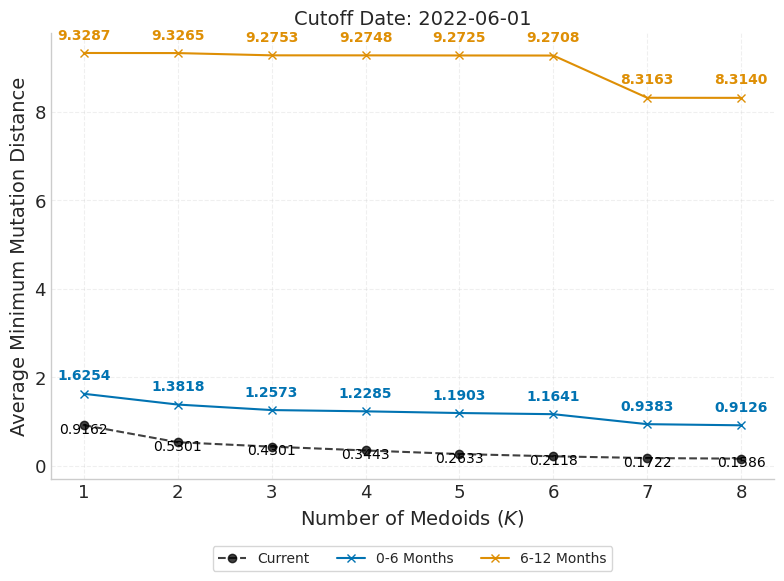

In [23]:
reference_evaluation_results = {}

plot_medoid_performance(
    medoid_evaluation_results=medoid_evaluation_results,
    cutoff_date=cutoff_date,
    reference_results=reference_evaluation_results,
)

Distance Comparison

In [24]:
def calculate_and_print_vaccine_medoid_distances(comparators, pam_results, id_to_seq):
    """
    Calculates Hamming distance between each comparator vaccine and each medoid.

    comparators: list of (label, vaccine_to_seq, vaccine_ids), e.g.
        [("FDA", clade_to_seq, recommended_strains), ("Pfizer", pfizer_to_seq, [pfizer_inn])]
    """

    def get_hamming(s1, s2):
        if len(s1) != len(s2):
            return None
        return sum(c1 != c2 for c1, c2 in zip(s1, s2))

    print(f"{'='*60}")
    print(f"{'VACCINE VS MEDOID HAMMING DISTANCES':^60}")
    print(f"{'='*60}\n")

    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"Configuration: K = {k}")
        print(f"{'-'*30}")

        for m_id in medoid_ids:
            m_seq = id_to_seq.get(m_id)
            if m_seq is None:
                print(f"  [!] Medoid {m_id} not found in id_to_seq.")
                continue

            print(f"  Medoid ID: {m_id}")

            for label, vaccine_to_seq, vaccine_ids in comparators:
                for vaccine_id in vaccine_ids:
                    v_seq = vaccine_to_seq.get(vaccine_id)
                    display_name = f"{label}: {vaccine_id}"
                    if v_seq is None:
                        print(f"    - vs {display_name:.<25} [!] Not found")
                        continue

                    dist = get_hamming(v_seq, m_seq)
                    if dist is None:
                        print(f"    - vs {display_name:.<25} Error: Length Mismatch")
                    else:
                        print(f"    - vs {display_name:.<25} Distance: {dist}")
            print()
        print(f"{'='*60}\n")


vaccine_comparators = [
    ("FDA", clade_to_seq, recommended_strains),
    ("Pfizer", pfizer_to_seq, [pfizer_inn]),
]
calculate_and_print_vaccine_medoid_distances(
    comparators=vaccine_comparators,
    pam_results=pam_results,
    id_to_seq=id_to_seq,
)

            VACCINE VS MEDOID HAMMING DISTANCES             

Configuration: K = 1
------------------------------
  Medoid ID: S_227455
    - vs FDA: BA.4................ Distance: 0
    - vs Pfizer: Famtozinameran... Distance: 1


Configuration: K = 2
------------------------------
  Medoid ID: S_227455
    - vs FDA: BA.4................ Distance: 0
    - vs Pfizer: Famtozinameran... Distance: 1

  Medoid ID: S_230196
    - vs FDA: BA.4................ Distance: 4
    - vs Pfizer: Famtozinameran... Distance: 5


Configuration: K = 3
------------------------------
  Medoid ID: S_227455
    - vs FDA: BA.4................ Distance: 0
    - vs Pfizer: Famtozinameran... Distance: 1

  Medoid ID: S_230196
    - vs FDA: BA.4................ Distance: 4
    - vs Pfizer: Famtozinameran... Distance: 5

  Medoid ID: S_184827
    - vs FDA: BA.4................ Distance: 3
    - vs Pfizer: Famtozinameran... Distance: 4


Configuration: K = 4
------------------------------
  Medoid ID: S_227455
   

PyR0 Fitness Score Comparisons

In [25]:
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")

Loaded 2474 PyR₀ mutation scores


In [26]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)

In [27]:
# --- Add mutation information to current sequences ---
fda_df = add_mutations_column(fda_df, clade_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
fda_df = add_fitness_scores_pyro(fda_df, mutation_score_dict_pyro)

pfizer_df = add_mutations_column(pfizer_df, pfizer_to_seq, refSeq)
pfizer_df = add_fitness_scores_pyro(pfizer_df, mutation_score_dict_pyro)

In [44]:
def print_fitness_scores(
    pam_results,
    recommended_strains,
    current_seq_df,
    fda_df,
    pfizer_df=None,
    oracle_pam_results=None,
    oracle_intervals=None,
):
    """
    Print CoVFit scores for every entity the report compares.

    Reference vaccines come first, then one block per K holding that K's scout
    medoids followed by the oracle medoids fit on each future window, so a single
    K can be read without scrolling. PyR0 is not shown: not every sequence has a
    PyR0 score, so the column was dropped from the report.
    """
    covfit_map = current_seq_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()
    fda_map = fda_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()
    pfizer_map = (
        pfizer_df.set_index("Sequence_ID")[FITNESS_COLUMN].to_dict()
        if pfizer_df is not None
        else {}
    )
    oracle_intervals = oracle_intervals or []
    oracle_pam_results = oracle_pam_results or {}
    oracle_labels = {"6M_1": "0-6 Months", "6M_2": "6-12 Months"}

    def fmt(value):
        return f"{value:.5f}" if isinstance(value, float) else value

    def print_ids(medoid_ids, indent="    "):
        for m_id in medoid_ids:
            score = fmt(covfit_map.get(m_id, "N/A (Not Found)"))
            print(f"{indent}ID: {m_id:.<18} CoVFit: {score}")

    print(f"{'='*60}")
    print(f"{'CoVFit SCORE EVALUATION':^60}")
    print(f"{'='*60}\n")

    print("FDA STRAIN SCORES")
    print(f"{'-'*30}")
    for strain in recommended_strains:
        print(f"  {strain:.<20} CoVFit: {fmt(fda_map.get(strain, 'N/A (Not Found)'))}")
    print()

    if pfizer_map:
        print("PFIZER VACCINE SCORES")
        print(f"{'-'*30}")
        for strain, score in pfizer_map.items():
            print(f"  {strain:.<20} CoVFit: {fmt(score)}")
        print()

    for k in sorted(pam_results.keys()):
        print(f"K = {k}")
        print(f"{'-'*30}")
        print("  VaccineScout")
        print_ids(pam_results[k].get("medoids", []))

        for oracle_interval in oracle_intervals:
            interval_results = oracle_pam_results.get(oracle_interval, {})
            if k not in interval_results:
                continue
            label = oracle_labels.get(oracle_interval, oracle_interval)
            print(f"  Oracle [{label}]")
            print_ids(interval_results[k].get("medoids", []))
        print()

    print(f"{'='*60}")


print_fitness_scores(
    pam_results,
    recommended_strains,
    current_seq_df,
    fda_df,
    pfizer_df,
    oracle_pam_results=oracle_pam_results,
    oracle_intervals=ORACLE_INTERVALS,
)

                  CoVFit SCORE EVALUATION                   

FDA STRAIN SCORES
------------------------------
  BA.4................ CoVFit: 0.53196

PFIZER VACCINE SCORES
------------------------------
  Famtozinameran...... CoVFit: 0.53131

K = 1
------------------------------
  VaccineScout
    ID: S_227455.......... CoVFit: 0.53196
  Oracle [0-6 Months]
    ID: S_227455.......... CoVFit: 0.53196
  Oracle [6-12 Months]
    ID: S_253647.......... CoVFit: 0.55366

K = 2
------------------------------
  VaccineScout
    ID: S_227455.......... CoVFit: 0.53196
    ID: S_230196.......... CoVFit: 0.47040
  Oracle [0-6 Months]
    ID: S_227455.......... CoVFit: 0.53196
    ID: S_184827.......... CoVFit: 0.44273
  Oracle [6-12 Months]
    ID: S_253647.......... CoVFit: 0.55366
    ID: S_266470.......... CoVFit: 0.54751

K = 3
------------------------------
  VaccineScout
    ID: S_227455.......... CoVFit: 0.53196
    ID: S_230196.......... CoVFit: 0.47040
    ID: S_184827.......... CoVFit: 